<a href="https://colab.research.google.com/github/Hailey9164/Data-Science-Group-Project/blob/main/CS2410GroupProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 2410 Group Project
## **Group Memebers:** Hailey Campbell, Frank Win, Joseph Yip

## Project 1

Section 1: What you expect to find

As far as I was able to see, there were no other analyses of this dataset. Some problems I think that might come out of this topic are that other factors may have a large impact on salary which will make it harder for us to answer our question precisely. As for analyses of related datasets, they tend to point out that unemployment rates increase the less education you have, maxing out at "less than high school" and median weekly earnings go up as well maxing out at "doctoral degree".

Section 2: Full EDA

Step 1:
Each row in the data represents one person. The identifiers are all unique mainly thanks to the "Salary" column. The dataset basically covers anyone in the US who went to school and got a job. Feature types are all fine. The outcome column is "Salary" and the explanatory columns are "Education Level", "Job Title", "Gender", and "Years of Experience" because we are trying to identify the impact of mainly education level on salaries.

Step 2:
I would say the strongest relationship is between Education Level and Salary. I would say that it's definitely a strong relationship and still holds within important subgroups, such as years of education. There were no relationships that I expected that I also wasn't able to find. While Education Level and Years of Experience both clearly have an effect on Salary, I think Job Title also confounds the relationship a good amount. I don't think my results disagree with anything that I read at all.

Step 3:
The distribution is skewed to the right obviously, because each level of education is considered better than the last and we know that has a correlation with salary. From the mean alone, a reader would probably get the idea that the small difference between Bachelor's and PhD means that PhD are not that much more likely to net you a job. I don't believe any transformation is warranted because the skew of the data already meets the expectations, with high school being far lower than the others and the rest of the data being close to symmetrical. The only group I am considering collapsing/dropping is gender because I don't expect it to have a large impact on my results and only has 2 options.

Step 4:
There is no missing data in my dataset. I'm going to use Tukey's Fences (1.5 * IQR) to determine what is and isn't an outlier because it's a popular choice for other datasets. There's not really a huge difference between the data set with and without outliers.

Oddities:
Rounded number salaries | Unknown | Keep, make sure everything else makes sense
Extremely high salaries (250k+) | Extreme? | Keep, make sure every other column matches

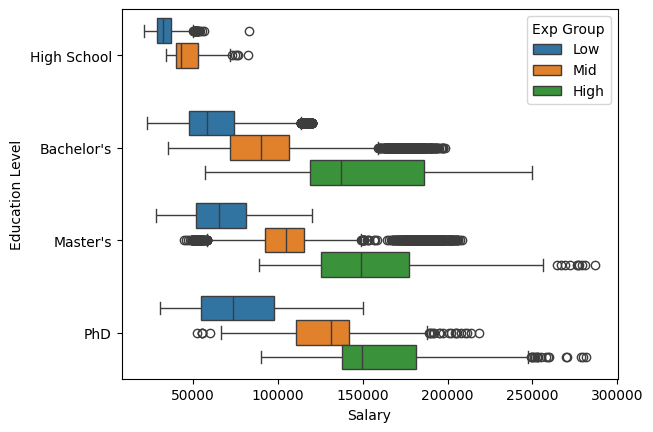

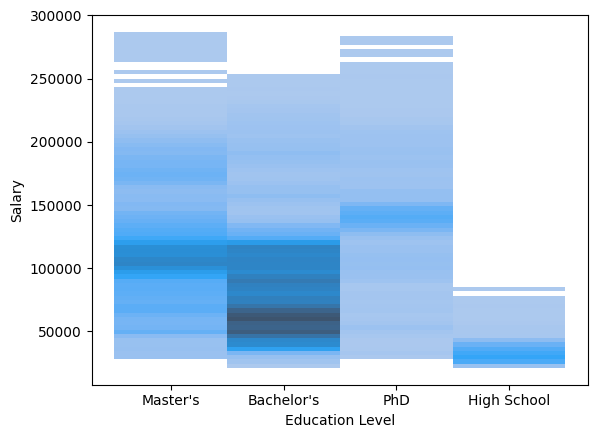

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
Exp Group              0
dtype: int64


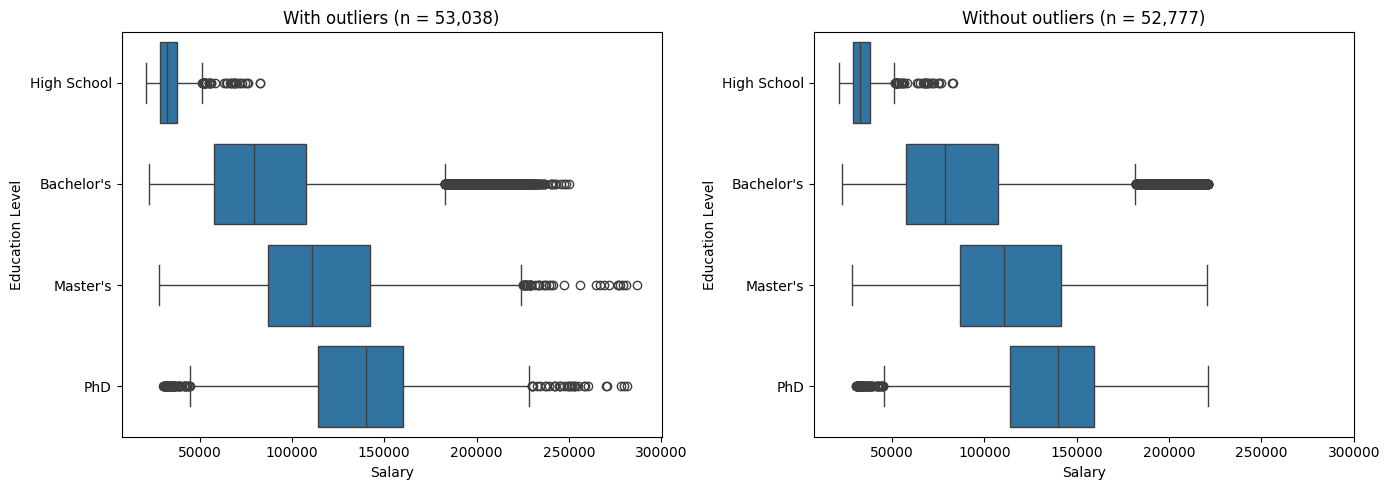

In [ ]:
from matplotlib import axes
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Section 2 Code
# Step 2
df = pd.read_csv('Salary-Data-50k+Records.csv')
df['Exp Group'] = pd.qcut(df['Years of Experience'], 3, labels=['Low', 'Mid', 'High'])

sns.boxplot(data=df, x='Salary', y='Education Level', hue='Exp Group',
            order=["High School", "Bachelor's", "Master's", "PhD"])
plt.figure()
sns.histplot(data=df, x='Education Level', y='Salary')
plt.show()

# Step 4
print(df.isna().sum())

def tukey(s):
    k = 1.5
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - k * iqr
    upper_bound = q3 + k * iqr
    return s[(s < lower_bound) | (s > upper_bound)]

outliers = tukey(df['Salary'])
df_trim = df.drop(outliers.index)
order = ["High School", "Bachelor's", "Master's", "PhD"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.boxplot(data=df, x='Salary', y='Education Level', order=order, ax=axes[0])
axes[0].set_title(f"With outliers (n = {len(df):,})")
sns.boxplot(data=df_trim, x='Salary', y='Education Level', order=order, ax=axes[1])
axes[1].set_title(f"Without outliers (n = {len(df_trim):,})")

plt.tight_layout()
plt.show()

Section 3: What the data is missing

I feel like the dataset in its current state answers our question well enough. If I had to change/add some variables though, there's a lot of things that affect salary besides education level. A derived variable we could use is starting age where we subtract years of experience from current age. This means if you had 5 years of experience and were 27, you started working at 22. We could use this variable to determine when certain people finished college/education. Some outside variables that could be nice to have would be location and employer. To control these, we would need columns like company size, industry, state, and city.

Derive: Starting age

Join in: Occupation-level wage, job-based stats

Can't get: State, city, major, employer

In [ ]:
# Section 3 Code
df1 = pd.read_csv('Salary-Data-50k+Records.csv')
df2 = pd.read_excel('national_M2025_dl.xlsx')

ref = df2[['OCC_TITLE', 'A_MEDIAN']].drop_duplicates('OCC_TITLE')

before = len(df1)
merged = df1.merge(ref, left_on='Job Title', right_on='OCC_TITLE', how='left', indicator=True)

print("Rows before:", before, "| after:", len(merged))
print(merged['_merge'].value_counts())

FileNotFoundError: [Errno 2] No such file or directory: 'national_M2025_dl.xlsx'

Section 4: Written analysis

Our team’s question is how education level affects salary. This dataset shows how salary differs across education levels among 53,038 employed people aged 19 to 55. The biggest thing I found is that salary rises with education level: median salary climbs from about $32.6k for High School to $79.3k for Bachelor’s, $110.8k for Master’s, and $139.9k for PhD, which the boxplot for salary by education level above shows. Experience plays some part in this, since High School workers average only 1.6 years of experience compared to 10.2 for PhDs. Within each experience group the ordering of education levels still holds, but the gaps shrink. Among workers with 0-3 years of experience, median pay gos from about $32k (High School) to $74k (PhD), and among those with 9 or more years, Bachelor’s, Master’s, and PhD holders earn about $137k, $149k, and $150k. Comparing people with similar experience is therefore the better way to estimate the education gap. The pattern isn't driven by extreme salaries. Salary is only mildly right-skewed (mean $99.7k, median $95.7k), and removing the 261 salaries flagged above roughly $221k moved every education level’s median by less than $500, so I kept them as senior pay (all have 10+ years of experience and important titles).
There's quite a lot of limitations to the dataset. The sample excludes workers over 55, and a complete file says nothing about who was never recorded, so comparisons against that group are less certain. Field of study, prior ability, family background, location, employer, and hours worked plausibly affect both who earns a degree and what they are paid, so these gaps should be read as associations, and the causal effect could be smaller or larger. If we continues with this dataset, our next step would be to join occupation-level wage benchmarks by job title and test whether the gaps survive when pay is expressed relative to the occupation’s typical wage. My first attempt matched 0 of 53,038 titles exactly, so we would need to try with a different dataset potentially.




Section 5: Viability case

After the cleaning plan, we are probably going to have the exact same or close to the same amount of rows, which is roughly 53k+, a good amount of rows to work with. There is nothing that our question needs that this data lacks unless there's a change in the question, and from my Section 3, it doesn't seem like a join would work with this, but it could work with similar datasets that have similar naming conventions. I would say the cleaning time is around 2-3 hours because there's a lot of rows with misspelled job titles. The dataset originates from Kaggle and is a remade version of another Kaggle dataset but with more contributors now and different columns. The data was collected in 2024 and there is no personal data included in it, so it should be fine to use and up to date.


In [ ]:
# Section 5 Code

# this is from the data viability and joins notebook
OUTCOME = "Salary"
EXPLANATORY = ["Years of Experience", "Education Level", "Job Title"]

def viability_report(df, outcome, explanatory, min_rows=200, min_cols=8):
    print(f"1. Opened: yes — {df.shape[0]} rows x {df.shape[1]} columns")
    print(f"2. Big enough? rows >= {min_rows}: {df.shape[0] >= min_rows} | columns >= {min_cols}: {df.shape[1] >= min_cols}")
    missing = [c for c in [outcome] + explanatory if c not in df.columns]
    print(f"3. Columns exist? {'yes' if not missing else 'MISSING: ' + str(missing)}")
    pct = (df[[outcome] + [c for c in explanatory if c in df.columns]].isna().mean() * 100).round(1)
    print("4. % missing in the columns that matter:")
    print(pct.to_string())
    print("5. Source: (write one sentence about who collected it, when, how)") # dataset is from Kaggle, collected by various contributors, and contains salary data for different job titles and education levels.
    print(f"6. Messy? duplicates={df.duplicated().sum()}, any impossible values? -> check describe() above") # no
    print("7. Anything you shouldn't have? (names, personal data, terms of use)") # no

viability_report(df, OUTCOME, EXPLANATORY)

1. Opened: yes — 53038 rows x 7 columns
2. Big enough? rows >= 200: True | columns >= 8: False
3. Columns exist? yes
4. % missing in the columns that matter:
Salary                 0.0
Years of Experience    0.0
Education Level        0.0
Job Title              0.0
5. Source: (write one sentence about who collected it, when, how)
6. Messy? duplicates=0, any impossible values? -> check describe() above
7. Anything you shouldn't have? (names, personal data, terms of use)


Section 6: Verdict and pitch

I think this dataset is a good choice for looking at how education level relates to salary. It has 53,038 records, which is large enough for us to work with. It includes the information we need, which is education level, years of experience, age, gender, job title, and salary. It’s also fairly clean, with no missing values, no duplicate rows, but some misspelled job titles. Education only has four categories, and salaries are spread out sensibly, with the average ($99.7k) close to the middle value ($95.7k).
It isn’t perfect though, education and experience overlap, since High School workers have only about 1.6 years of experience on average compared with 10.2 for PhDs, and about 5% of people are listed at exactly 0 years. It also lacks location, employer, and field of study. But these problems are small and well understood. The zero-experience rows are mostly young, entry-level workers (ages 19 to 30) with lower pay, which is what we’d expect. And because the dataset includes experience, we can adjust for the overlap directly.




Section 7: Team decision

The team decided to go with my dataset because the "Years of Experience" column could be a good addition to our analysis in combination with our main focus which is education level. The other dataset we considered, which came from my teammate Hailey listed salaries as averages instead of individual people, but it could be a good backup dataset incase we find that my dataset is difficult or unfavorable to work with. It does also show how inflation affects salaries over the years. My dataset is more relevant to the question we have though. I agree with the decision to go with my dataset because it has a lot of records, and the inclusion of people with 0.0 years of experience could show what salaries look like for people who are just starting to work.

## CS2410 Probability Team Worksheet

In [ ]:
import pandas as pd
from scipy.stats import bernoulli, binom, norm
import matplotlib.pyplot as plt
import numpy as np
df = pd.read_csv("/content/Salary-Data-50k+Records.csv")

In [ ]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,26,Female,Master's,junior human resources generalist,1.0,30011.88
1,41,Female,Bachelor's,financial manager,17.0,228990.56
2,29,Female,Bachelor's,junior software engineerineer,2.0,55417.62
3,28,Female,Bachelor's,software engineerineer,3.0,82120.85
4,26,Male,PhD,sales representative,0.0,52131.91


# Q1. A sample space and one event

**Random process:** pick one of the 53,038 employee records at random.

**Sample space:** S = all 53,038 rows, each equally likely.

**Event A:** The employee earns more than $100,000.

In [ ]:
import pandas as pd
A = df['Salary'] > 100000
P_A = A.mean()   # 0.4658
print(f"P(A) = {P_A:.4f}")

P(A) = 0.4658


About 46.58% of employees in the dataset earn over $100k.

# Q2. An "at least one" question, via the complement

**Question:** If I pick 5 employees at random, what is the chance at least one earns over $100k?

In [ ]:
print(1 - (1 - P_A) ** 5)   # 0.9565

0.9564885302876427


P(none) = (1 − 0.466)⁵ = 0.534⁵ = 0.044
P(at least one) = 1 − 0.044 = 0.956

In a group of 5, it is very likely (about 96%) that at least one person earns over $100k. That is much higher than the 47% for a single pick, because more picks give more chances.

# Q3. Are two events independent?

**Event B:** The employee has a Master’s or PhD.

Education Level is a categorical column, as the worksheet suggests.

In [ ]:
B = df['Education Level'].isin(["Master's", 'PhD'])
P_A_given_B = A[B].mean()      # 0.6932
P_A_given_notB = A[~B].mean()  # 0.2935

print(f"P(A|B) = {P_A_given_B:.4f}")
print(f"P(A|not B) = {P_A_given_notB:}")

pd.crosstab(B, A, margins=True)

P(A|B) = 0.6932
P(A|not B) = 0.29353876739562623


Salary,False,True,All
Education Level,,,
False,21321,8859,30180
True,7013,15845,22858
All,28334,24704,53038


P(A | B) = 15,845 / 22,858 = 0.693

P(A | not B) = 8,859 / 30,180 = 0.294

P(A) = 0.466

**Independent?** No. 0.693 is far from 0.466. If A and B were independent, P(A and B) would equal or at least close P(A) × P(B) = 0.201, but the actual value is 0.299. Knowing someone has an advanced degree raises the chance of a $100k+ salary from 47% to 69%. Knowing they don’t drops it to 29%, which is the clean story the worksheet describes.

# Q4. Flip it with Bayes' rule

In [ ]:
A1 = A[B].mean() * B.mean()
A2 = A[~B].mean() * (1-B.mean())
PA = A1 + A2
P_B_given_A = A1 / PA
print (A1)
print (A2)
print (PA)
print (P_B_given_A)

0.29874806742335686
0.1670311851879784
0.46577925261133524
0.6413941062176166


# Q5. A yes/no column as Bernoulli(p)

In [ ]:
p = (df["Gender"] == "Male").sum() / len(df)
var = p * (1-p)
print (p)
print (var)

0.5114823334213205
0.24986815601920162


The mean is the proportion of males in the dataset, which is just over half. The variance is very close to 0.25, which supports the fact that the split of males and females is nearly even.

# Q6. Count of yeses in 20 rows as binomial

In [ ]:
# sampling 20 rows
expected = 20 * p
print(f"Expected males: {expected}")

probability = 1 - binom.cdf(9, n=20, p=p)  # 10 - 1 is 9. 10 because at least half of the sample (20) is male/yes

sims = [(df['Gender'].sample(20) == "Male").sum() for _ in range(2000)]
i = np.mean(np.array(sims) >= 10)

print(f"SciPy probability: {probability}")
print(f"Simulation probability: {i}")

Expected males: 10.229646668426412
SciPy probability: 0.628034145841205
Simulation probability: 0.613


# Q7. Is a numeric column roughly normal?

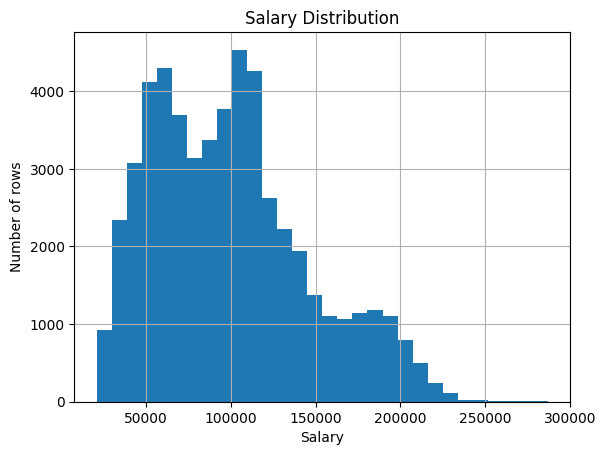

In [ ]:
# Testing salary column
salary = df["Salary"]
salary_mean = df["Salary"].mean()
salary_sd = df["Salary"].std()

salary.hist(bins = 30)
plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of rows")
plt.show()

two peaks indicate it is not normally distributed

In [ ]:
z = (salary - salary_mean) / salary_sd # z-score

outliers = df.loc[abs(z) > 2].copy()  # creating a new df containing z-scores to determine outliers outliers
outliers["z_score"] = z.loc[outliers.index]
display(outliers) # displays all outliers

print(f"Number of rows past ±2 SD: {len(outliers)}") # displays number of outliers

df[abs(z) > 2]  # proportion of salaries within 1, 2, 3 sd of mean. measure against 0.68, 0.95, 0.99
for k in (1, 2, 3):
  print(k, (abs(z) < k).mean())

,Age,Gender,Education Level,Job Title,Years of Experience,Salary,z_score
1,41,Female,Bachelor's,financial manager,17.0,228990.56,2.803244
11,39,Female,Bachelor's,financial manager,15.0,210819.20,2.409141
35,44,Male,Master's,marketing manager,19.0,205880.22,2.302023
42,44,Male,Master's,marketing manager,20.0,203781.11,2.256497
54,32,Male,Bachelor's,product manager,9.0,205077.01,2.284603
...,...,...,...,...,...,...,...
52905,37,Male,Bachelor's,financial manager,15.0,211753.99,2.429415
52959,47,Female,PhD,directorector of marketing,19.0,207421.66,2.335454
52989,50,Female,PhD,directorector of human resources,20.0,192036.63,2.001781
52997,35,Male,Master's,product manager,11.0,192699.38,2.016155


Number of rows past ±2 SD: 2499
1 0.6657490855612956
2 0.9528828387194087
3 0.9990572796862627


2499 rows are above +2 standard deviations and none are below -2. About 68%, 95% and 99% fell within one, two, and three standard deviations, and are close to the 68-95-99.7 rule. Although it is close to the rule, the shape indicates it is not normally distributed.

# Your one-page summary

Team: Hailey Campbell, Frank Win, Joseph Yip Dataset: Salary-Data-50kRecords.csv  Rows: 53,038

Q1 Event A = "The employee earns more than \$100,000". P(A) = 0.466. In words: 47% of employees in the dataset earn over $100k.

Q2 At least one _one earner over $100k in 5 picks: P = 0.956. Computed as 1 - (1 - 0.466)^5 = 1 - 0.044.

Q3 Event B = "the employee has a Master's or PhD". P(A|B) = 0.693 vs P(A) = 0.466. Independent? No Why: Knowing someone has an advanced degree raises the chance of a $100k+ salary from 47% to 69%, and P(A | not B) is only 29%, so education clearly moves the odds.

Q4 P(B|A) by Bayes = 0.640. P(A) built as 0.297 + 0.167 = 0.464. Direct count
check: 52,049

Q5 Bernoulli column: Gender. p = 0.512. Variance 0.250 means: the data is evenly spread

Q6 X ~ binomial(20, 0.5115). Expected 10.23. P(X >= 10) = 0.6280. Simulation
gave 0.634.

Q7 Column: Salary. Shape: not normal(two peaks). Within 1/2/3 SD: 66.57% / 95.29% / 99.91%.
Outliers: 2,499

Normal is / is not a good model because: not; the histogram is not symmetric

One thing this told us about our project question: there is a wide variety of salaries and the overall average is likely related to other factors like education and experience levels. To better understand salaries and salary outlooks, we need to compare salaries within those groups

## Other Analysis

In [ ]:
import pandas as pd
from scipy.stats import bernoulli, binom, norm
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df = pd.read_csv("/content/Salary-Data-50k+Records.csv")

### Salary vs. Education level

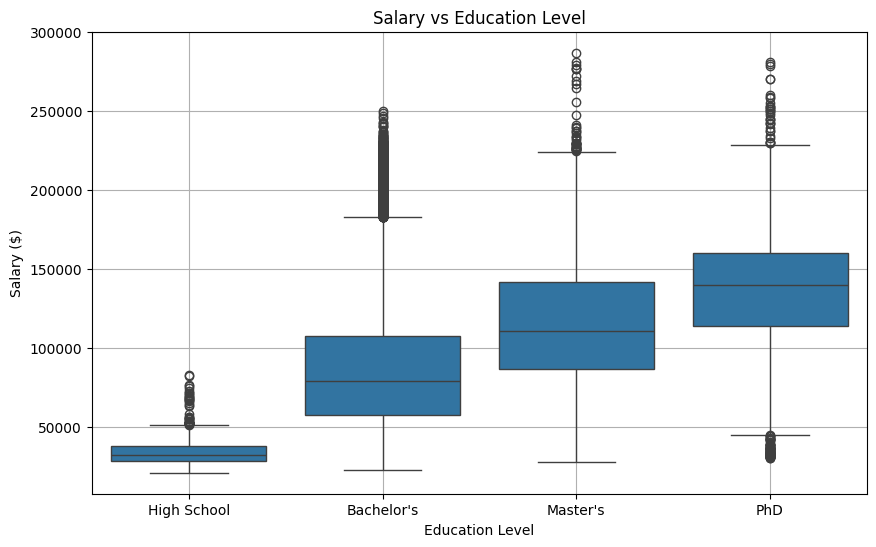

In [ ]:
df = df.dropna(subset=["Education Level", "Salary"])
df["Education Level"] = df["Education Level"].str.replace(" Degree", "").str.replace("phD", "PhD")
# Create box plot
order = ["High School", "Bachelor's", "Master's", "PhD"]
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Education Level",
    y="Salary",
    order=order
)
plt.title("Salary vs Education Level")
plt.xlabel("Education Level")
plt.ylabel("Salary ($)")
plt.grid(True)
plt.show()

In [ ]:
# Drop missing values and merge variant labels (e.g. "Bachelor's Degree" -> "Bachelor's")
df = df.dropna(subset=["Education Level", "Salary"])
df["Education Level"] = df["Education Level"].str.replace(" Degree", "").str.replace("phD", "PhD")
# Summary statistics by education level
order = ["High School", "Bachelor's", "Master's", "PhD"]
print(df.groupby("Education Level")["Salary"].agg(["count", "mean", "median", "std", "min", "max"]).reindex(order).round(0))

                 count      mean    median      std      min       max
Education Level                                                       
High School       2297   33673.0   32564.0   7203.0  21075.0   83005.0
Bachelor's       27883   87285.0   79343.0  39872.0  22747.0  250000.0
Master's         17074  116011.0  110830.0  42912.0  28083.0  286961.0
PhD               5784  137972.0  139943.0  40626.0  30465.0  281373.0


### Salary vs. Experience

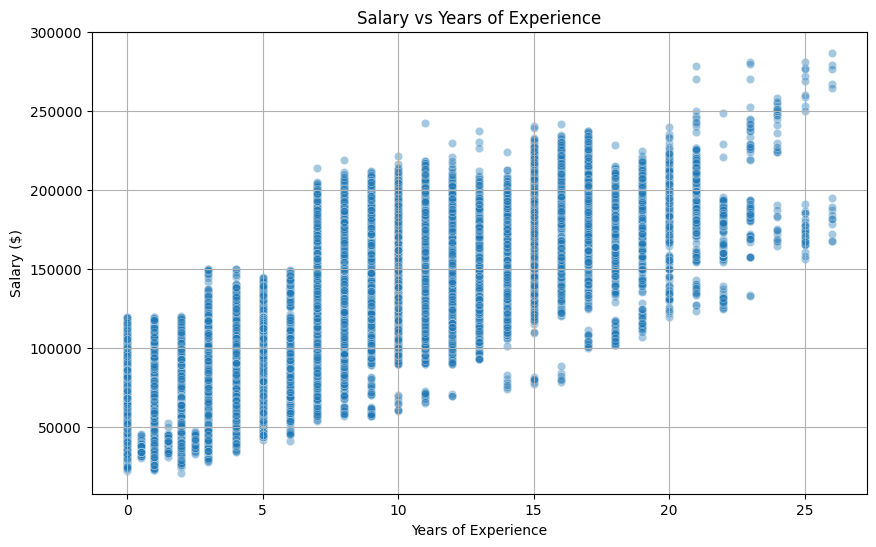

In [ ]:
# Create scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Years of Experience",
    y="Salary",
    alpha=0.4
)

plt.title("Salary vs Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.grid(True)
plt.show()

In [ ]:
# Drop missing values
df = df.dropna(subset=["Years of Experience", "Salary"])
# Summary statistics
print(df[["Years of Experience", "Salary"]].describe().round(1))
# Correlation between experience and salary
r, r_p = stats.pearsonr(df["Years of Experience"], df["Salary"])
rho, rho_p = stats.spearmanr(df["Years of Experience"], df["Salary"])
print("\nPearson correlation: r =", round(r, 3), ", p =", r_p)
print("Spearman correlation: rho =", round(rho, 3), ", p =", rho_p)
# Linear regression: how much does salary change per extra year of experience?
fit = stats.linregress(df["Years of Experience"], df["Salary"])
print("\nSalary change per extra year of experience: $", round(fit.slope))
print("R-squared:", round(fit.rvalue ** 2, 3))
# Average salary by experience bracket
df["Experience Bracket"] = pd.cut(df["Years of Experience"], bins=[-1, 2, 5, 10, 15, 20, 50],
                                  labels=["0-2", "3-5", "6-10", "11-15", "16-20", "20+"])
print("\n", df.groupby("Experience Bracket", observed=True)["Salary"].agg(["count", "mean", "median"]).round(0))

       Years of Experience    Salary
count              53038.0   53038.0
mean                   6.4   99738.3
std                    5.1   46108.1
min                    0.0   21074.9
25%                    2.0   62344.8
50%                    5.0   95679.0
75%                    9.0  125894.5
max                   26.0  286960.9

Pearson correlation: r = 0.847 , p = 0.0
Spearman correlation: rho = 0.854 , p = 0.0

Salary change per extra year of experience: $ 7676
R-squared: 0.718

                     count      mean    median
Experience Bracket                           
0-2                 13834   57401.0   53500.0
3-5                 14607   77177.0   75139.0
6-10                13349  118010.0  112503.0
11-15                7933  149327.0  143935.0
16-20                2698  182334.0  186839.0
20+                   617  189056.0  183343.0


### Salary vs. Gender

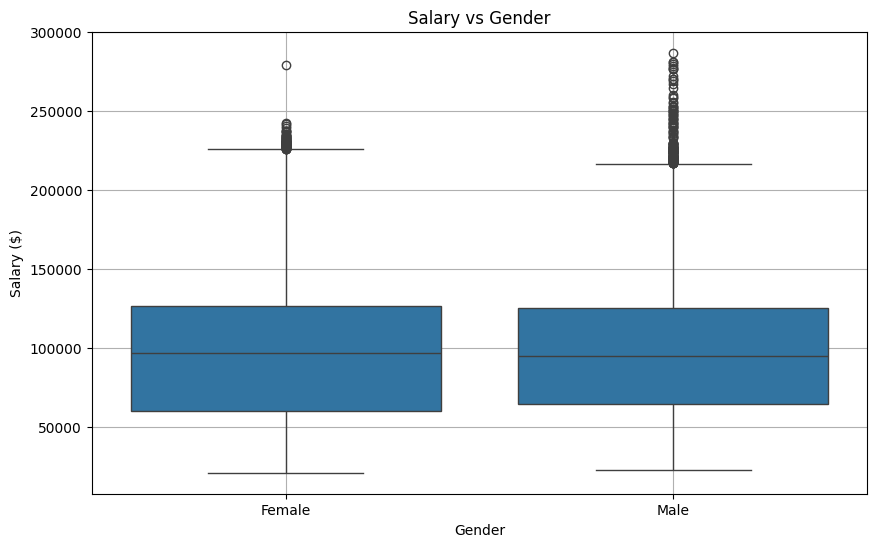

In [ ]:
df = df.dropna(subset=["Gender", "Salary"])
# Create box plot
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Gender",
    y="Salary"
)
plt.title("Salary vs Gender")
plt.xlabel("Gender")
plt.ylabel("Salary ($)")
plt.grid(True)
plt.show()

In [ ]:
from scipy import stats
# Load the dataset
# Drop missing values
df = df.dropna(subset=["Gender", "Salary"])
# Summary statistics by gender
print(df.groupby("Gender")["Salary"].agg(["count", "mean", "median", "std", "min", "max"]).round(0))
# Compare the two groups
male = df[df["Gender"] == "Male"]["Salary"]
female = df[df["Gender"] == "Female"]["Salary"]
print("\nMean gap (Male - Female): $", round(male.mean() - female.mean()))
print("Median gap (Male - Female): $", round(male.median() - female.median()))

        count      mean   median      std      min       max
Gender                                                      
Female  25910   99384.0  96660.0  47232.0  21075.0  279266.0
Male    27128  100076.0  94833.0  45006.0  22733.0  286961.0

Mean gap (Male - Female): $ 692
Median gap (Male - Female): $ -1827


### Salary vs. Education Level at 0 years of experience

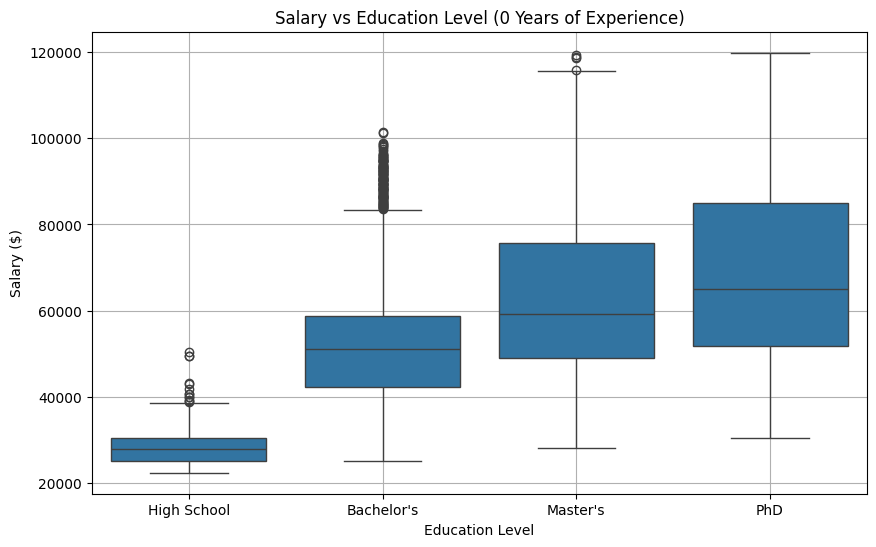

In [ ]:
# Drop missing values and merge variant labels (e.g. "Bachelor's Degree" -> "Bachelor's")
df = df.dropna(subset=["Education Level", "Salary", "Years of Experience"])
df["Education Level"] = df["Education Level"].str.replace(" Degree", "").str.replace("phD", "PhD")
# Keep only people with 0 years of experience
df = df[df["Years of Experience"] == 0]
# Create box plot
order = ["High School", "Bachelor's", "Master's", "PhD"]
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Education Level",
    y="Salary",
    order=order
)
plt.title("Salary vs Education Level (0 Years of Experience)")
plt.xlabel("Education Level")
plt.ylabel("Salary ($)")
plt.grid(True)
plt.show()

In [ ]:
# Drop missing values and merge variant labels (e.g. "Bachelor's Degree" -> "Bachelor's")
df = df.dropna(subset=["Education Level", "Salary", "Years of Experience"])
df["Education Level"] = df["Education Level"].str.replace(" Degree", "").str.replace("phD", "PhD")
# Keep only people with 0 years of experience
df = df[df["Years of Experience"] == 0]
# Summary statistics by education level
order = ["High School", "Bachelor's", "Master's", "PhD"]
print(df.groupby("Education Level")["Salary"].agg(["count", "mean", "median", "std", "min", "max"]).reindex(order).round(0))

                 count     mean   median      std      min       max
Education Level                                                     
High School        411  28433.0  27982.0   4246.0  22428.0   50410.0
Bachelor's        1267  53058.0  51216.0  16118.0  25105.0  101420.0
Master's           677  62758.0  59265.0  21331.0  28083.0  119275.0
PhD                395  69119.0  65061.0  23096.0  30465.0  119814.0
